In [17]:
import pandas as pd
import numpy as np
import torch 
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [2]:
# Load the training data
train_df = pd.read_csv("../data/raw/train_FD001.txt", sep = r'\s+', header = None)

# Assign column names to the dataframe
column_names = [
    "unit_id",
    "cycle",
    "operational_setting_1",
    "operational_setting_2",
    "operational_setting_3",
] + [f"sensor_{i}" for i in range(1, 22)]

train_df.columns = column_names

# Remaining useful life (RUL) calculation
train_df["RUL"] = train_df.groupby("unit_id")["cycle"].transform("max") - train_df["cycle"]

print(train_df.shape)
print(train_df[["unit_id", "cycle", "RUL"]].head())

(20631, 27)
   unit_id  cycle  RUL
0        1      1  191
1        1      2  190
2        1      3  189
3        1      4  188
4        1      5  187


In [3]:
# Define the sensor columns to be used as features
sensor_columns = [
    "sensor_2", "sensor_3", "sensor_4",
    "sensor_6", "sensor_7", "sensor_8",
    "sensor_9", "sensor_11", "sensor_12",
    "sensor_13", "sensor_14", "sensor_15",
    "sensor_17", "sensor_20", "sensor_21"
]

X = train_df[sensor_columns]
y = train_df["RUL"]

print(X.shape)
print(y.shape)

(20631, 15)
(20631,)


In [4]:
# Split the data by engine
engine_ids = train_df["unit_id"].unique() # Extract only the distinct engine IDs

train_ids, val_ids = train_test_split(
    engine_ids,
    test_size = 0.2,
    random_state = 42
)

print(len(train_ids))
print(len(val_ids))

80
20


In [5]:
# Create masks for training and validation engines
train_mask = train_df["unit_id"].isin(train_ids)
val_mask = train_df["unit_id"].isin(val_ids)

# Separate features and targets 
X_train = X[train_mask]
y_train = y[train_mask]
X_val = X[val_mask]
y_val = y[val_mask]

# Check for overlap between training and validation sets
overlap = np.intersect1d(train_ids, val_ids)

print("Overlapping engines:", overlap)
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)

Overlapping engines: []
Training shape: (16561, 15)
Validation shape: (4070, 15)


In [6]:
# Feature scaling by standardization (z-score normalization)
scaler = StandardScaler()

# Fit the training data and validation data then transform it
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

# Confirm whether the data is scaled
print("Training mean:",X_train_scaled.mean(axis = 0))
print("Training std:",X_train_scaled.std(axis = 0))

Training mean: [-2.19757255e-14 -1.42185775e-14 -4.40029364e-15 -3.89931060e-12
 -4.51802381e-14 -1.11748237e-12  1.12375674e-14 -3.51474313e-15
  1.05493779e-13  7.27613610e-12  3.93349182e-15 -4.22215383e-14
 -1.64341700e-14 -7.87041600e-15  2.57118562e-14]
Training std: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [7]:
# Convert features to tensors
X_train_tensor = torch.tensor(X_train_scaled, dtype = torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype = torch.float32)

# Convert targets to tensors
y_train_tensor = torch.tensor(y_train.values, dtype = torch.float32)
y_val_tensor = torch.tensor(y_val.values, dtype = torch.float32)

# Reshape targets to match the network output
y_train_tensor = y_train_tensor.unsqueeze(1)
y_val_tensor = y_val_tensor.unsqueeze(1)

print("Training features:", X_train_tensor.shape)
print("Training targets:", y_train_tensor.shape)
print("Validation features:", X_val_tensor.shape)
print("Validation targets:", y_val_tensor.shape)

Training features: torch.Size([16561, 15])
Training targets: torch.Size([16561, 1])
Validation features: torch.Size([4070, 15])
Validation targets: torch.Size([4070, 1])


In [8]:
# Pair features with their corresponding RUL targets
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

# Create mini-batches
batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size = batch_size,
    shuffle = True
)

val_loader = DataLoader(
    val_dataset,
    batch_size = batch_size,
    shuffle = False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 259
Validation batches: 64


In [9]:
X_batch, y_batch = next(iter(train_loader))

print("Input batch shape:", X_batch.shape)
print("Target batch shape:", y_batch.shape)

Input batch shape: torch.Size([64, 15])
Target batch shape: torch.Size([64, 1])


In [10]:
# Neural Network implementation
class RULPredictor(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer1 = nn.Linear(15, 64)
        self.layer2 = nn.Linear(64, 32)
        self.output = nn.Linear(32, 1)

    # Forward pass (How the data flows through the network)
    def forward(self, x):
        x = torch.relu(self.layer1(x))
        x = torch.relu(self.layer2(x))
        x = self.output(x)

        return x 


# Instantiate and structure inspection
model = RULPredictor()
print(model)


RULPredictor(
  (layer1): Linear(in_features=15, out_features=64, bias=True)
  (layer2): Linear(in_features=64, out_features=32, bias=True)
  (output): Linear(in_features=32, out_features=1, bias=True)
)


In [11]:
# Loss function and optimizer
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001)

In [12]:
# Test the neural network with one batch
predictions = model(X_batch)

print("Predictions shape:", predictions.shape)
print("First five predictions:", predictions[:5])
print("First five actual RUL values:", y_batch[:5])

Predictions shape: torch.Size([64, 1])
First five predictions: tensor([[ 0.0545],
        [-0.0061],
        [-0.1842],
        [ 0.0698],
        [ 0.0388]], grad_fn=<SliceBackward0>)
First five actual RUL values: tensor([[158.],
        [107.],
        [197.],
        [ 66.],
        [150.]])


In [13]:
# Calculate loss for the 1st batch
loss = loss_fn(predictions, y_batch)

print("Initial batch MSE:", loss.item())
print("Initial batch RMSE:", np.sqrt(loss.item()))

Initial batch MSE: 21513.349609375
Initial batch RMSE: 146.674297712227


In [14]:
# Train the neural network for one epoch
model.train() # Set the model to training mode

total_loss = 0.0

for X_batch, y_batch in train_loader:
    # Clear the gradients from the previous batch
    optimizer.zero_grad()

    # Forward pass
    predictions = model(X_batch)

    # Calculate loss
    loss = loss_fn(predictions, y_batch)

    # Backpropagation
    loss.backward()

    # Update weights and biases
    optimizer.step()

    # Accumulate loss accounting for batch size
    total_loss += loss.item() * X_batch.size(0)

train_mse = total_loss / len(train_dataset)
train_rmse = np.sqrt(train_mse)

print("Training MSE:", train_mse)
print("Training RMSE:", train_rmse)

Training MSE: 9067.726922556194
Training RMSE: 95.22461300817238


In [15]:
# Evaluate the model on validation data
model.eval() # Set the model to evaluation mode

total_val_loss = 0.0

with torch.no_grad(): # Disable gradient calculation for validation
    for X_batch, y_batch in val_loader:
        # Forward pass
        predictions = model(X_batch)

        # Calculate validation loss
        loss = loss_fn(predictions, y_batch)

        # Accumulate validation loss accounting for batch size
        total_val_loss += loss.item() * X_batch.size(0)

val_mse = total_val_loss / len(val_dataset)
val_rmse = np.sqrt(val_mse)

print("Validation MSE:", val_mse)
print("Validation RMSE:", val_rmse)

Validation MSE: 2442.5950783169533
Validation RMSE: 49.42261707272242


In [16]:
# Start a fresh training loop for multiple epochs
torch.manual_seed(42) # For reproducibility of random initialization

# Training phase
model = RULPredictor() # Re-initialize the model
total_train_loss = 0.0

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001)

num_epochs = 30

train_losses = []
val_losses = []

for epoch in range(num_epochs):
    model.train() # Set the model to training mode
    total_loss = 0.0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        predictions = model(X_batch)
        loss = loss_fn(predictions, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * X_batch.size(0)

    # Validation phase
    model.eval() # Set the model to evaluation mode
    total_val_loss = 0.0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            predictions = model(X_batch)
            loss = loss_fn(predictions, y_batch)
            total_val_loss += loss.item() * X_batch.size(0)

    # Calculate RMSE for this epoch
    train_rmse = np.sqrt(total_loss / len(train_dataset))
    val_rmse = np.sqrt(total_val_loss / len(val_dataset))

    # Store results in the empty lists
    train_losses.append(train_rmse)
    val_losses.append(val_rmse)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train RMSE: {train_rmse: .2f} | "
        f"Val RMSE: {val_rmse: .2f}"
    )
    

Epoch 1/30 | Train RMSE:  97.80 | Val RMSE:  56.32
Epoch 2/30 | Train RMSE:  54.92 | Val RMSE:  39.90
Epoch 3/30 | Train RMSE:  46.70 | Val RMSE:  35.83
Epoch 4/30 | Train RMSE:  44.46 | Val RMSE:  35.31
Epoch 5/30 | Train RMSE:  44.06 | Val RMSE:  35.21
Epoch 6/30 | Train RMSE:  43.95 | Val RMSE:  35.12
Epoch 7/30 | Train RMSE:  43.59 | Val RMSE:  35.01
Epoch 8/30 | Train RMSE:  43.15 | Val RMSE:  34.78
Epoch 9/30 | Train RMSE:  42.97 | Val RMSE:  34.95
Epoch 10/30 | Train RMSE:  42.86 | Val RMSE:  35.02
Epoch 11/30 | Train RMSE:  42.83 | Val RMSE:  34.67
Epoch 12/30 | Train RMSE:  42.77 | Val RMSE:  34.79
Epoch 13/30 | Train RMSE:  42.75 | Val RMSE:  34.82
Epoch 14/30 | Train RMSE:  42.73 | Val RMSE:  34.63
Epoch 15/30 | Train RMSE:  42.70 | Val RMSE:  34.71
Epoch 16/30 | Train RMSE:  42.66 | Val RMSE:  34.54
Epoch 17/30 | Train RMSE:  42.64 | Val RMSE:  34.57
Epoch 18/30 | Train RMSE:  42.61 | Val RMSE:  34.72
Epoch 19/30 | Train RMSE:  42.61 | Val RMSE:  34.63
Epoch 20/30 | Train R

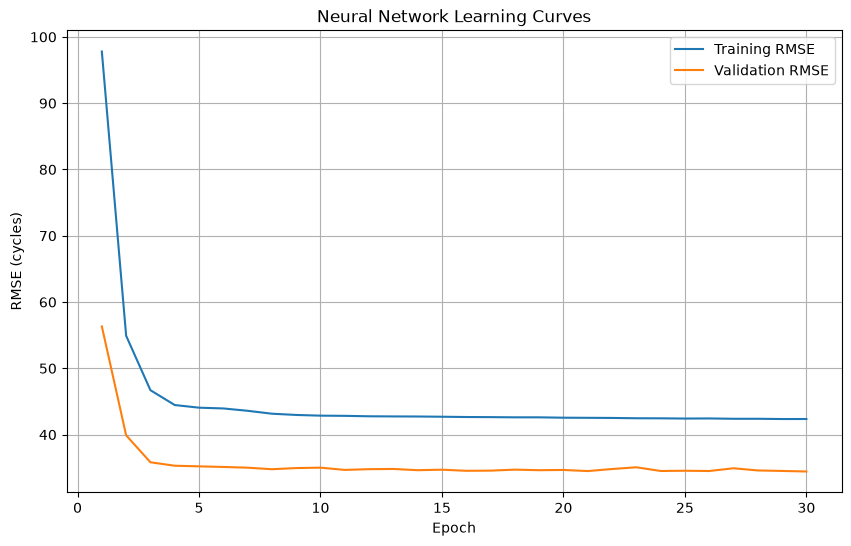

In [18]:
# Plot the training and validation RMSE over epochs
epochs = range(1, len(train_losses) + 1)
plt.figure(figsize = (10, 6)) 

plt.plot(epochs, train_losses, label = "Training RMSE") 
plt.plot(epochs, val_losses, label = "Validation RMSE")

plt.xlabel("Epoch")
plt.ylabel("RMSE (cycles)")
plt.title("Neural Network Learning Curves")
plt.legend()
plt.grid(True)

plt.show()

In [19]:
# Evaluate the final model on the training dataset
model.eval()

total_train_loss = 0.0

with torch.no_grad():
    for X_batch, y_batch in train_loader:
        predictions = model(X_batch)
        loss = loss_fn(predictions, y_batch)

        total_train_loss += loss.item() * X_batch.size(0)

final_train_mse = total_train_loss / len(train_dataset)
final_train_rmse = np.sqrt(final_train_mse)

print(f"Final Training RMSE: {final_train_rmse:.2f}")

Final Training RMSE: 42.26


In [20]:

print("Training RUL statistics:")
print(y_train.describe())

print("\nValidation RUL statistics:")
print(y_val.describe())

Training RUL statistics:
count    16561.000000
mean       108.377815
std         69.639875
min          0.000000
25%         51.000000
50%        103.000000
75%        156.000000
max        361.000000
Name: RUL, dtype: float64

Validation RUL statistics:
count    4070.000000
mean      105.488698
std        65.659973
min         0.000000
25%        50.000000
50%       101.000000
75%       153.000000
max       268.000000
Name: RUL, dtype: float64


In [21]:
# Generate predictions for validation engines
model.eval()

with torch.no_grad():
    val_predictions = model(X_val_tensor)

print("Predictions shape:", val_predictions.shape)
print("First five predictions:", val_predictions[:5])
print("First five actual RUL values:", y_val_tensor[:5])

Predictions shape: torch.Size([4070, 1])
First five predictions: tensor([[167.2150],
        [172.7124],
        [173.4064],
        [181.7960],
        [168.5931]])
First five actual RUL values: tensor([[191.],
        [190.],
        [189.],
        [188.],
        [187.]])


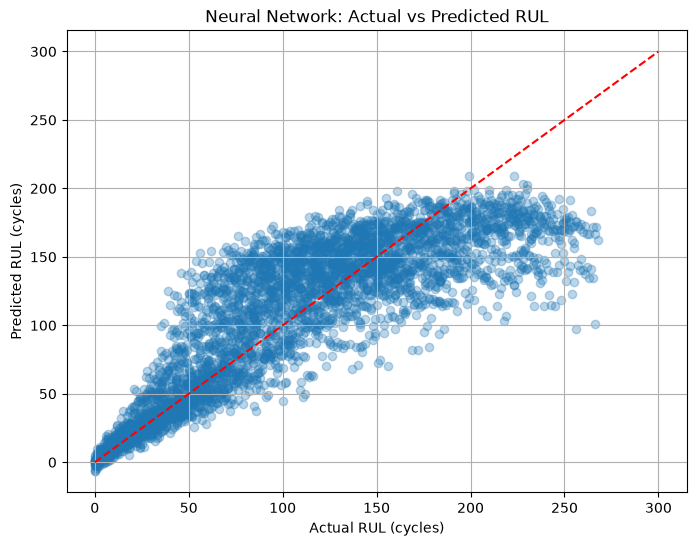

In [24]:
# Convert PyTorch tensors to NumPy arrays
actual_rul = y_val_tensor.numpy().flatten()
predicted_rul = val_predictions.numpy().flatten()

# Plot actual vs predicted RUL
plt.figure(figsize = (8, 6))

plt.scatter(actual_rul, predicted_rul, alpha = 0.3)

# Perfect prediction reference line
plt.plot([0, 300], [0, 300], color = "red", linestyle = "--")

plt.xlabel("Actual RUL (cycles)")
plt.ylabel("Predicted RUL (cycles)")
plt.title("Neural Network: Actual vs Predicted RUL")
plt.grid(True)

plt.show()

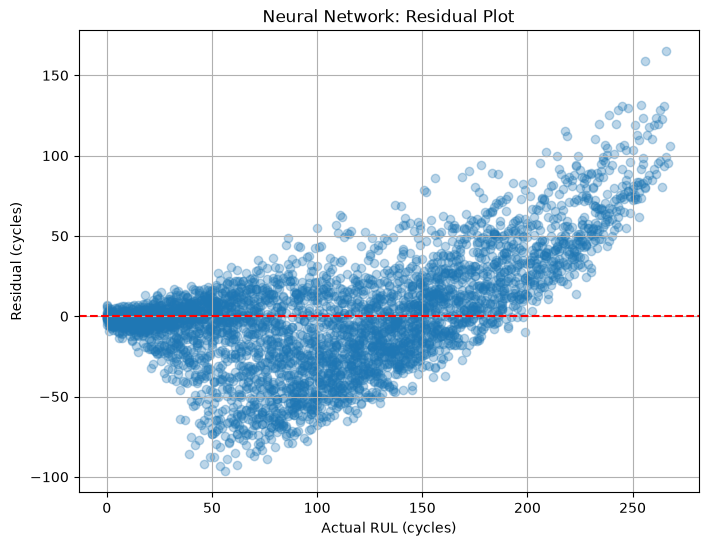

In [25]:
# Calculate residuals
residuals = actual_rul - predicted_rul

# Plot residuals
plt.figure(figsize = (8, 6))

plt.scatter(actual_rul, residuals, alpha = 0.3)

# Zero-error reference line
plt.axhline(y = 0, color = "red", linestyle = "--")

plt.xlabel("Actual RUL (cycles)")
plt.ylabel("Residual (cycles)")
plt.title("Neural Network: Residual Plot")
plt.grid(True)

plt.show()